# Introduction to `treetensorcomp`

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Quick-start: functions and TCI

First, let's get up and running with a simple example.

This collaboration focuses on the representation, approximation and (amplitude-encoded) state preparation of continuum functions. In this library, functions are abstracted `treetensorcomp.quantics.functions.QuanticsFunction` classes. These handle the mapping between continuum variables and Hilbert space index settings. Let's build a simple `QuanticsFunction` of one variable:

In [2]:
from treetensorcomp.quantics.functions import QuanticsFunction
from treetensorcomp.quantics.index_settings import ExternalIndexSetting
import numpy as np
import matplotlib.pyplot as plt

def f(q, sigma):
    return np.exp(-0.5 * ((q - 0.3) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

testfunc = QuanticsFunction(f, ['q'], {'sigma': 0.1}, variable_domains=[(0,1)])

Many classes in this library have inline representations to quickly inspect objects you're working with when working in an iPython notebook, e.g.:


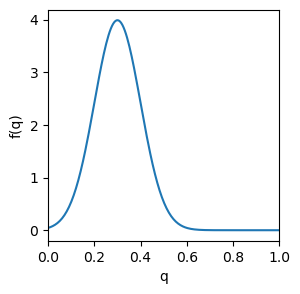

In [3]:
testfunc

Underlying the tree tensor networks in this library are TTNGraphs, which encode metadata about the tensor network's graph structure on a NetworkX base.

We can build and inspect these graphs:

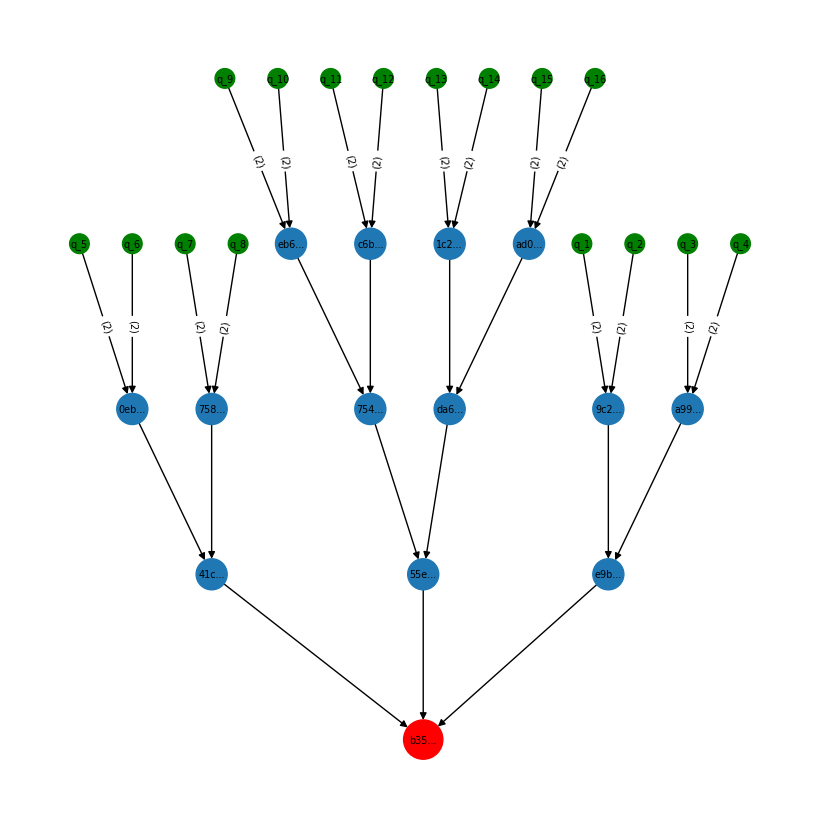

In [4]:
from treetensorcomp.tensor_networks.tree_graphs import TTNGraph

test_ttn_graph = TTNGraph.from_binary_tree(branching_ratio=2, depth=4)
test_ttn_graph.draw()

We can build a tree tensor network consisting of random tensors from this graph structure:

In [5]:
from treetensorcomp.tensor_networks.tree_tensor_network import TreeTensorNetwork

test_ttn = TreeTensorNetwork.random_tree(test_ttn_graph)

and inspect its bond dimension which is now shown in the graph:

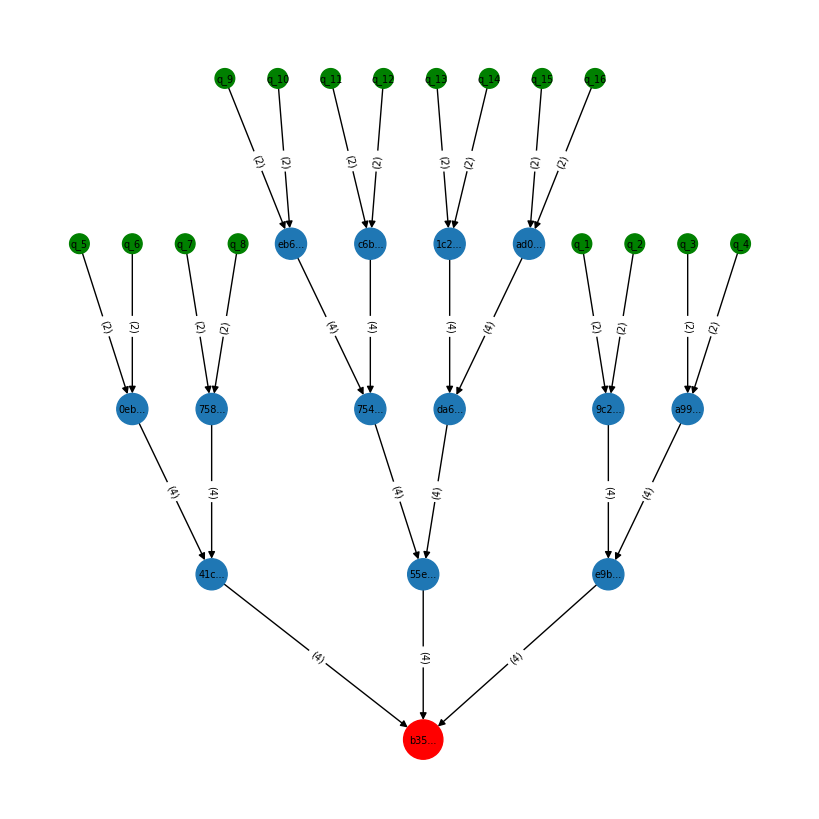

In [6]:
test_ttn.ttn_graph.draw(show_edge_ids=False, show_bond_dimensions=True)

Let's plot the values of this tree for $q\in [0,1]$. We need to define an ExternalIndexSetting for the correct binary bit values that form these values of $q$, and then can evaluate the TreeTensorNetwork at those.

Text(0.5, 1.0, 'Function values of random TTN')

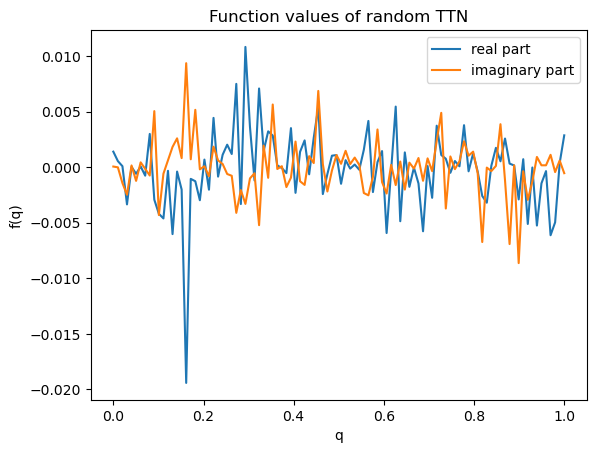

In [7]:
from treetensorcomp.quantics.index_settings import ExternalIndexSetting

q_vals = np.linspace(0,1,100)

index_setting = ExternalIndexSetting.from_variable_values('q', 16, q_vals)
f_vals = test_ttn.evaluate_index_setting(index_setting)

plt.plot(q_vals, np.real(f_vals), label='real part'); plt.plot(q_vals, np.imag(f_vals), label='imaginary part')
plt.xlabel('q'); plt.ylabel('f(q)')
plt.legend()
plt.title('Function values of random TTN')

Now let's try to construct a low-bond-dimension TTN that approximates `testfunc` well. The process of tensor cross-interpolation is abstracted by the `Interpolator` class, which takes a tree tensor network and a target function and performs iterative sweeps (2-site TCI in reset mode) to refine the approximation.

Text(0.5, 1.0, 'Function values of TCI-refined TTN')

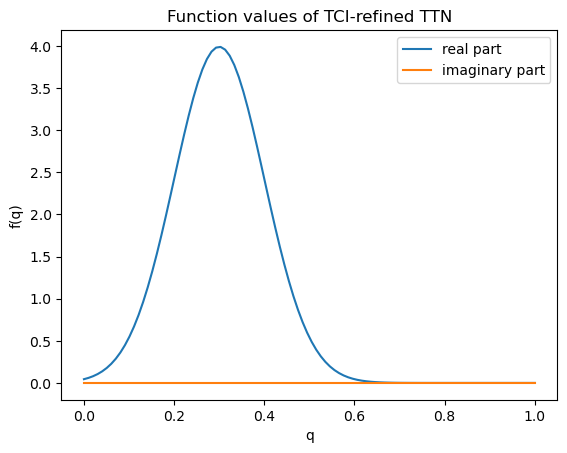

In [8]:
from treetensorcomp.tci.interpolation import Interpolator

test_interpolator = Interpolator(test_ttn, testfunc, error_tol=1e-12)
test_interpolator.tensor_cross_interpolation(n_sweeps=15)

f_vals_tci = test_interpolator.ttn.evaluate_index_setting(index_setting)

plt.plot(q_vals, np.real(f_vals_tci), label='real part'); plt.plot(q_vals, np.imag(f_vals_tci), label='imaginary part')
plt.xlabel('q'); plt.ylabel('f(q)')
plt.legend()
plt.title('Function values of TCI-refined TTN')

Nice, it approximated it well. Let's check the error:

Text(0, 0.5, 'error')

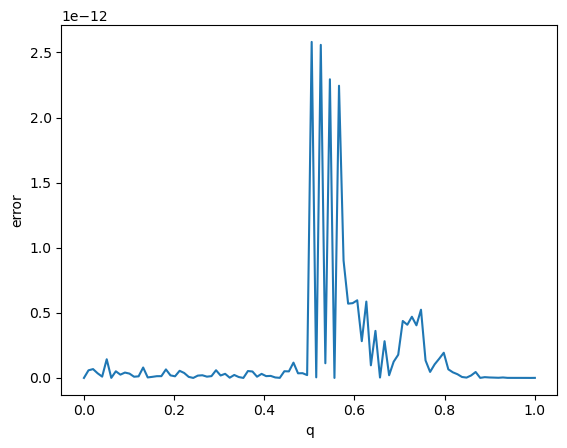

In [9]:
f_vals_exact = testfunc.evaluate_index_setting(index_setting)

plt.plot(q_vals, np.abs(f_vals_exact - f_vals_tci), label='error')
plt.xlabel('q'); plt.ylabel('error')

## Quick-start: clustering for tree structure optimization

TCI requires a tree structure as input (i.e. a TTNGraph in this library). The bond dimension will depend heavily on having a connectivity structure in the tensor network that is somehow reflective of the underlying entanglement. A function that is simple (i.e. low bond dimension) for one tree structure might have far higher bond dimension in another. This protocol aims to discover a near-optimal structure to produce TTNs with sparser representation.

Usually, placing bits in order of significance on an MPS is optimal for a single-variable function. Let's try this for a highly correlated quadrivariate function, with variables $a$, $b$, $c$, $d$. We'll use a multinormal distribution, drawn from the Lewandowski-Kurowicka-Joe distribution.

In [10]:

from treetensorcomp.quantics.common_distributions import multinormal_distribution

# Code below will generate a random distribution if you want one
#import tensorflow_probability as tfp
#dist = tfp.distributions.LKJ(4, 1)
#sigma = dist.sample().numpy()

# Saved instance of the covariance matrix
sigma = np.array([[ 1., -0.5887003, 0.06007266, 0.77436894], [-0.5887003, 1., 0.27487615, -0.4010326 ], [ 0.06007266, 0.27487615, 1., -0.17109713], [ 0.77436894, -0.4010326, -0.17109713, 1. ]])
var_names = ['a', 'b', 'c', 'd']
mu = np.array([0.5, -0.1, 0.0, 0.2])

test_dist = multinormal_distribution(var_names, mu, sigma, name='multi_normal')


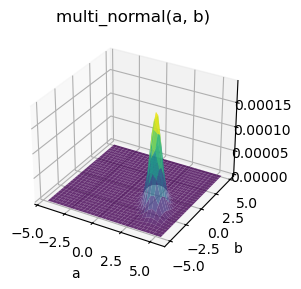

In [11]:
test_dist

Now, we'll identify the pairwise entanglement between the qubits. Here this is done with Monte Carlo (fine since there is no sign problem), but if one has access to a TTN or MPS form of the state, it can be computed noiselessly using efficient tensor contractions.

All of this is abstracted in a Clusterer class instance:

In [12]:
from treetensorcomp.structural_optimization.clustering import Clusterer

clusterer = Clusterer(test_dist, 10, monte_carlo_samples=50000)

We can look at the entanglement structure from the 'Boolean Fourier entropy':

/Users/matt/Documents/treetensorcomp/treetensorcomp/structural_optimization/clustering.py:359: RuntimeWarning: divide by zero encountered in log
  plt.matshow(np.log(affinity_matrix))


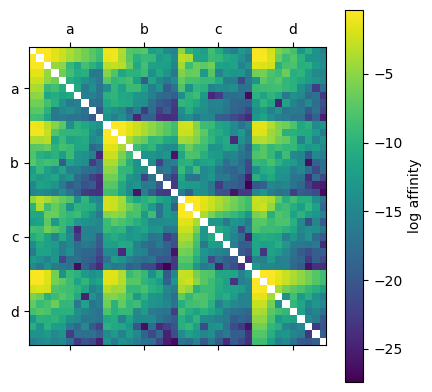

In [14]:
clusterer.plot_affinity_matrix(clusterer.projector_entropy_matrix())

Then we can use a recursive spectral clustering approach to turn this into an approximately optimal TTNGraph structure:

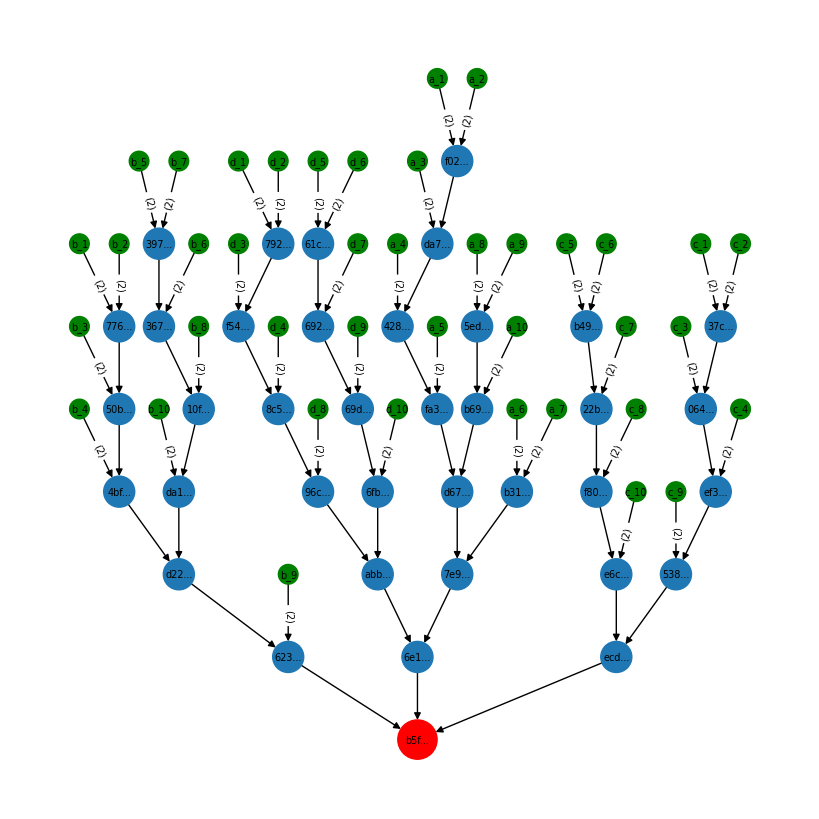

In [15]:
cluster_ttng = clusterer.divisive_ttn_graph(clusterer.projector_entropy_matrix())
cluster_ttng.draw()

We should compare this to the most performant previously used ansatz network structure, the comb (arXiv:2410.03572):

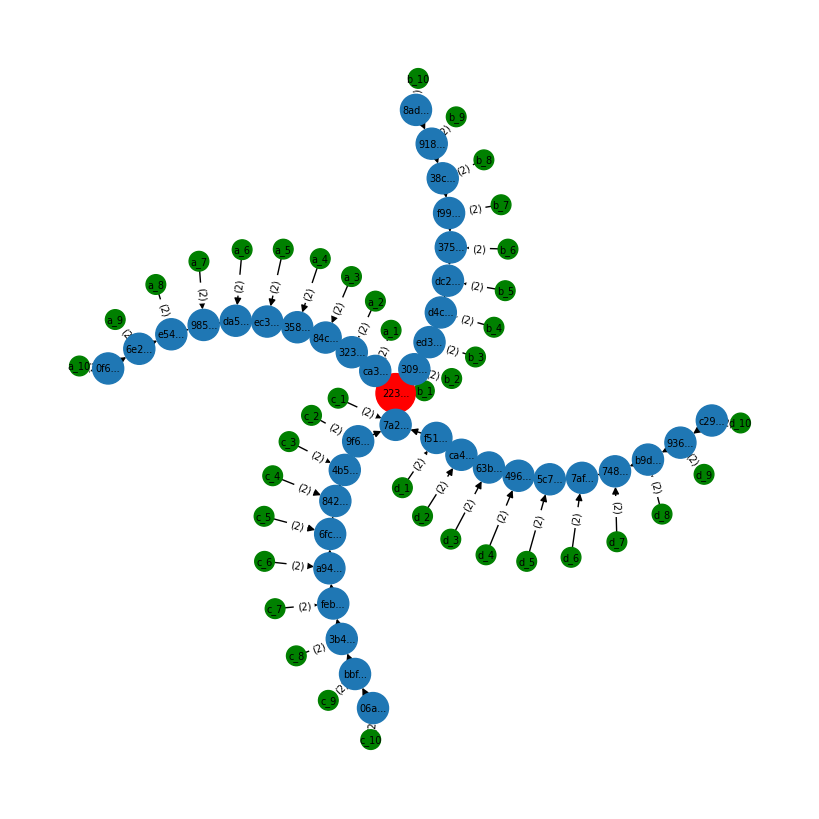

In [16]:
comb_graph = TTNGraph.comb(variables=var_names, precisions=10)
comb_graph.draw()

We can compare the results of TCI onto these two network structures. For SCENT:

In [17]:
from treetensorcomp.tensor_networks.tree_tensor_network import TreeTensorNetwork
from treetensorcomp.tci.interpolation import Interpolator

cluster_ttn = TreeTensorNetwork.random_tree(cluster_ttng)
cluster_interpolator = Interpolator(cluster_ttn, test_dist, error_tol = 1e-8)
cluster_interpolator.tracked_tci(n_sweeps = 5)

Sweeps: 100%|██████████| 5/5 [02:48<00:00, 33.62s/sweep]


And for the comb TTN:

In [18]:
comb_network = TreeTensorNetwork.random_tree(comb_graph)
comb_interpolator = Interpolator(comb_network, test_dist, error_tol = 1e-8)
comb_interpolator.tracked_tci(n_sweeps = 5)

Sweeps: 100%|██████████| 5/5 [04:02<00:00, 48.41s/sweep]


We can see that SCENT does much better (factor of ~2.5 compression in this case). Indeed, both of these are much better than MPS, which has poor performance due to the linear topology being very unsuitable:

In [19]:
mps_graph = TTNGraph.matrix_product_network(variables=var_names, precisions=10, ordering='interleaved')
mps_network = TreeTensorNetwork.random_tree(mps_graph)
mps_interpolator = Interpolator(mps_network, test_dist, error_tol = 1e-8)
mps_interpolator.tracked_tci(n_sweeps = 5)

Sweeps: 100%|██████████| 5/5 [07:19<00:00, 87.81s/sweep] 


For the same function, MPS requires 64.7MB, comb requires 3.31MB, SCENT requires 1.34MB. This size would be roughly proportional to the gate count in an exact decomposition.

We can also check the error profile of these interpolations:

In [21]:
from treetensorcomp.quantics.index_settings import ExternalIndexSetting

test_setting = ExternalIndexSetting.random_index_setting(var_names, [10,10,10,10], count=10000)

comb_deltas = test_dist.evaluate_index_setting(test_setting) - comb_interpolator.ttn.evaluate_index_setting(test_setting)
cluster_deltas = test_dist.evaluate_index_setting(test_setting) - cluster_interpolator.ttn.evaluate_index_setting(test_setting)
mps_deltas = test_dist.evaluate_index_setting(test_setting) - mps_interpolator.ttn.evaluate_index_setting(test_setting)

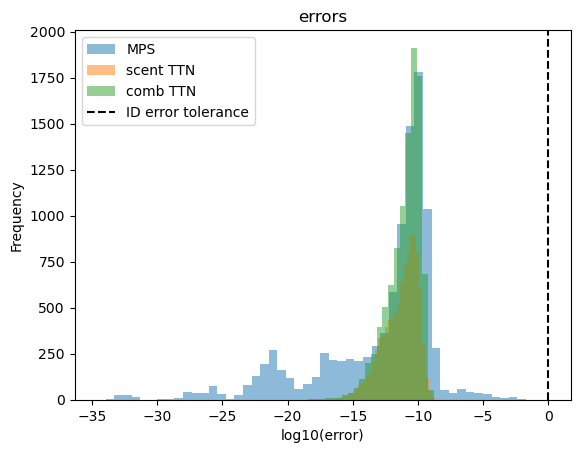

In [24]:

plt.hist(np.log10(np.abs(mps_deltas)), bins=50, label='MPS', alpha=0.5)
plt.hist(np.log10(np.abs(cluster_deltas)), bins=50, label='scent TTN', alpha=0.5)
plt.hist(np.log10(np.abs(comb_deltas)), bins=50, label='comb TTN', alpha=0.5)

plt.axvline(1e-8, color='k', linestyle='--', label='ID error tolerance')

plt.xlabel('log10(error)')
plt.ylabel('Frequency')
plt.title('errors')
plt.legend()
plt.show()

Looks like the MPS actually hadn't even converged at $\chi=915$ - so it's really not suitable for multivariate functions with strong correlations!